In [1]:
import cv2      # OpenCV 라이브러리
import numpy as np
import matplotlib.pyplot as plt

# 드라이브에 있는 파일 접근에 필요함
from pathlib import Path
from google.colab import drive

In [2]:
# 드라이브에 있는 작업 폴더 이동
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리/picture

Mounted at /content/drive
/content/drive/MyDrive/Colab_AI 영상처리/picture


In [17]:
# 이미지 경로 읽기
Image_Path = Path('beagle.jpg')
assert Image_Path.exists(), '이미지 파일이 없습니다.'
  # 이미지 경로 못 읽어낼 때, 예외 처리

# 이미지 읽기 :: cv2.imread()

In [18]:
# 위 경로에 따라, 이미지 읽어서 numpy 배열로 변환
image_bgr = cv2.imread(str(Image_Path))   # 이미지를 파랑->초록->빨강 읽어들임

if image_bgr is None:
  raise FileNotFoundError('이미지를 읽지 못했습니다.')

print(image_bgr)
# 3차원으로 읽어냄
# [세로_크기][가로_크기][3]
#   [3] -> 채널([0] 파랑 -> [1] 초록 -> [2] 빨강) 수

[[[  1   1   1]
  [  1   1   1]
  [  1   1   1]
  ...
  [ 66  51  35]
  [ 66  51  35]
  [ 65  50  34]]

 [[  1   1   1]
  [  1   1   1]
  [  1   1   1]
  ...
  [ 71  55  38]
  [ 73  55  38]
  [ 70  54  37]]

 [[  1   1   1]
  [  1   1   1]
  [  1   1   1]
  ...
  [ 83  62  40]
  [ 85  62  40]
  [ 82  61  39]]

 ...

 [[ 29  26  35]
  [ 22  21  25]
  [ 41  39  38]
  ...
  [ 52  61  70]
  [ 73  88  97]
  [ 88 104 116]]

 [[ 26  26  32]
  [ 30  29  31]
  [ 68  68  62]
  ...
  [ 52  61  71]
  [ 71  84  98]
  [ 82  97 113]]

 [[ 30  31  35]
  [ 47  49  49]
  [ 93  93  87]
  ...
  [ 49  58  68]
  [ 68  81  97]
  [ 80  94 112]]]


# 이미지 출력 :: cv2.cvtColor()

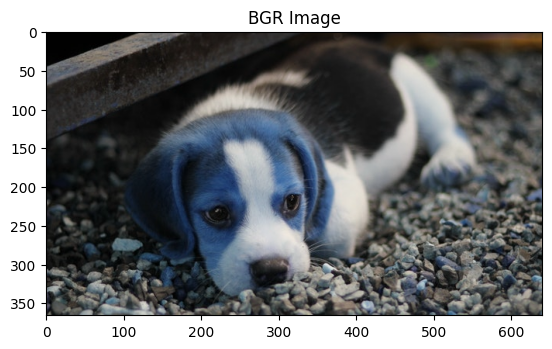

In [9]:
# 이미지 읽을 땐 BGR        [0]파랑, [1]초록, [2]빨강 수치로 표현
# 이미지 출력할 땐 RGB      [0]빨강, [1]초록, [2]파랑으로 전제 깔고 표현
#     => 읽을때랑 출력할때랑 방식이 다름 -> 색에 왜곡
plt.imshow(image_bgr)
plt.title('BGR Image')
plt.show()

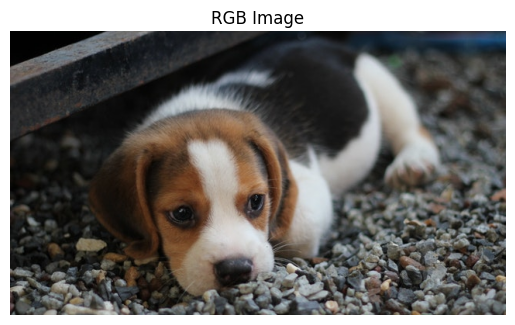

In [11]:
image_rgb = cv2.cvtColor(
    image_bgr,
    cv2.COLOR_BGR2RGB     # RGB로 변환
)
# [0]파랑, [1]초록, [2]빨강
#     => [0]빨강, [1]초록, [2]파랑 변환

plt.imshow(image_rgb)
plt.title('RGB Image')
plt.axis('off')     # 눈금표시 없애줌
plt.show()

In [16]:
# numpy 배열 정보 비교
# (세로크기, 가로크기, 채널수(색 표현))
print('BGR 이미지:', image_bgr.shape)
print('RGB 이미지:', image_rgb.shape)

# 일정 픽셀값 비교 (차이 있을수도 없을수도)
print('BGR 픽셀:', image_bgr[300][500])
print('RGB 픽셀:', image_rgb[300][500])
# 빨강 얼마 들어가고... 파랑 얼마 들어가고... 초록 얼마 들어가고...
#     => 각 픽셀의 색상 결정

BGR 이미지: (366, 640, 3)
RGB 이미지: (366, 640, 3)
BGR 픽셀: [40 39 35]
RGB 픽셀: [35 39 40]


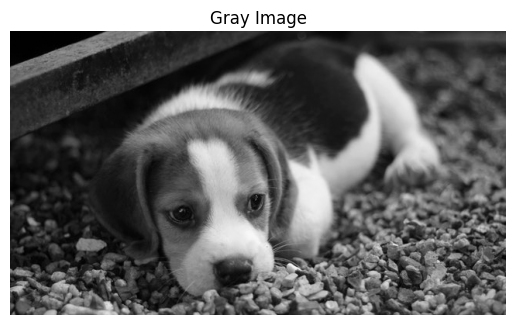

컬러: (366, 640, 3)
흑백: (366, 640)


In [27]:
# 문제
# 위 numpy 배열에 대해, 흑백으로 이미지 출력하기

# image_gray = cv2.cvtColor(
#     image_bgr,
#     cv2.COLOR_BGR2GRAY      # BGR -> 흑백 변환 (BGR to GRAY)
# )
image_gray = cv2.cvtColor(
    image_rgb,
    cv2.COLOR_RGB2GRAY      # RGB -> 흑백 변환   (RGB to GRAY)
)

#plt.imshow(image_gray)      # 가짜 흑백으로 출력됌
plt.imshow(image_gray, cmap='gray')     # 흑백으로 표현해줄 것을 명시 (cmap값 원인)
plt.title('Gray Image')
plt.axis('off')
plt.show()

# 컬러 numpy 배열, 흑백 numpy 배열 비교
print('컬러:', image_bgr.shape)
print('흑백:', image_gray.shape)    # 채널수에 대한 데이터가 X (색 표현X)

# 이미지 화질 변경(해상도 크기 변경) :: cv2.resize()

원본: (366, 640, 3)
축소본: (60, 100, 3)


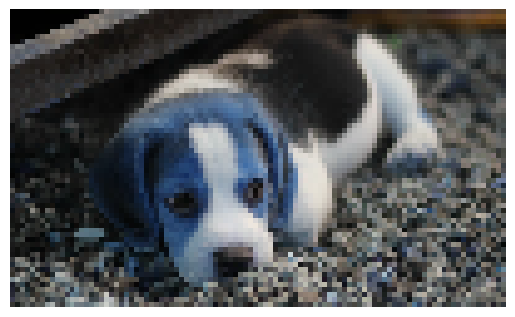

In [30]:
small_image = cv2.resize(image_bgr, (100, 60)) # 가로를 100, 세로를 60 설정

print('원본:', image_bgr.shape)
print('축소본:', small_image.shape)     # numpy 배열의 가로, 세로 크기 달라짐

plt.imshow(small_image)
plt.axis('off')
plt.show()
# 픽셀의 개수가 줄고, 픽셀의 하나 크기가 커짐

(60, 100, 3)
(720, 1200, 3)


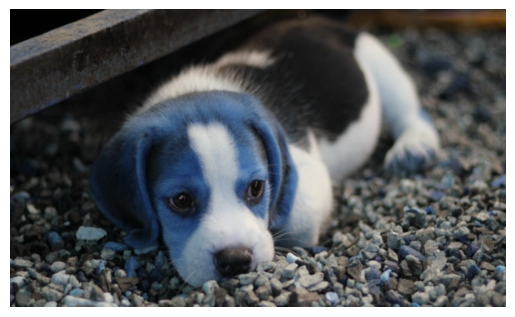

In [33]:
# small_image에 대해서, 확대 작업 진행 (가로를 1200으로, 세로를 720으로)
# shape값 비교 + 이미지 출력

big_image = cv2.resize(small_image, (1200, 720))
# big_image = cv2.resize(image_bgr, (1200, 720))
#   2개 big_image의 결과가 다름

print(small_image.shape)      # 가로 100, 세로 60
print(big_image.shape)        # 가로 1200, 세로 720

plt.imshow(big_image)
plt.axis('off')
plt.show()

# 원본보다는 선명하지만, 흐릿한 느낌이 있음
#    1개의 픽셀 정보를 12개로 쪼갠 상황

# 이미지 영역 선택 (슬라이싱)

원본 크기: (366, 640, 3)
슬라이싱 크기: (183, 320, 3)


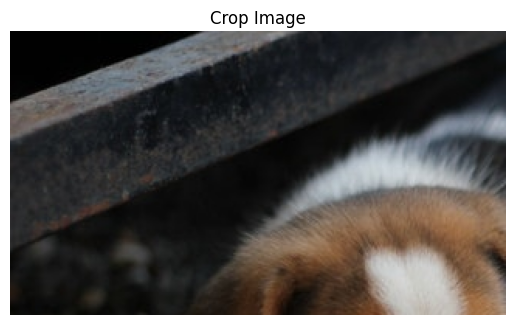

In [36]:
print('원본 크기:', image_rgb.shape)

# shape에서, 너비/높이 값 추출
h, w = image_rgb.shape[:2]    # 0번~2번 이전까지의 값 불러오기
  # shape[0] -> h 저장
  # shape[1] -> w 저장

# 슬라이싱 결과를 crop에 저장 (image_rgb는 numpy 배열)
#   """  행 번호 :: 세로 상의 위치
#        열 번호 :: 가로 상의 위치   """
crop = image_rgb[0 : h//2, 0 : w//2]

print('슬라이싱 크기:', crop.shape)

plt.imshow(crop)
plt.title('Crop Image')
plt.axis('off')
plt.show()

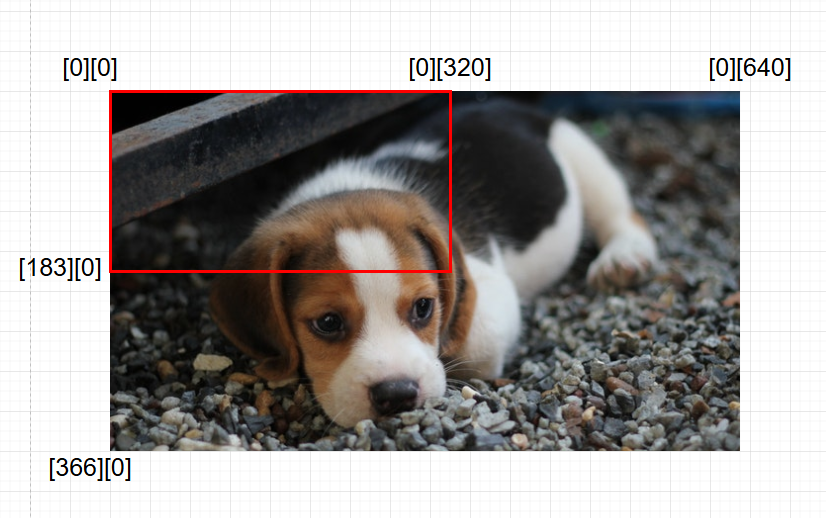